# TP2 — Clasificación de textos con redes neuronales MLP

**Redes Neuronales | 20 Newsgroups**

En este trabajo se entrena una red neuronal multicapa (*Multilayer Perceptron*, MLP) para clasificar documentos en 20 categorías. Partimos de una representación TF-IDF fija, evaluamos distintas arquitecturas y optimizadores mediante Optuna, estudiamos el sobreajuste y reservamos el conjunto de test para la evaluación final.

**Recorrido:** preparación de datos → definición de la red → entrenamiento piloto → búsqueda de hiperparámetros → análisis → sobreajuste → evaluación final.

# 1.Configuración inicial

Importamos las bibliotecas, fijamos la semilla aleatoria, elegimos CPU o GPU y preparamos las carpetas. La semilla favorece la reproducibilidad, aunque no garantiza resultados idénticos en todos los dispositivos.

In [ ]:
!pip install -q optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.7 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
from pathlib import Path
import time
import json
import shutil

import re
import random
import numpy as np
import copy
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

import optuna

import sqlite3

## 1.1Configuración global y Drive

In [ ]:
# Montar Google Drive
drive.mount("/content/drive")

# Semilla y dispositivo
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Mounted at /content/drive
Usando dispositivo: cuda


In [ ]:
# Carpeta principal del TP2
BASE_DIR = Path("/content/drive/MyDrive/Facultad documentos/20266/2C/16.32 Redes neuronales/tp/TP2")

# Subcarpetas
RESULTS_DIR = BASE_DIR / "resultados"
MODELS_DIR = BASE_DIR / "modelos"
BACKUP_DIR = BASE_DIR / "backups"

for folder in [BASE_DIR, RESULTS_DIR, MODELS_DIR, BACKUP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Base de Optuna en el almacenamiento local de Colab
LOCAL_DB = Path("/content/optuna_mlp.db")
BACKUP_DB = BACKUP_DIR / "optuna_mlp.db"


print("Carpeta principal:", BASE_DIR)
print("Base de Optuna:", LOCAL_DB)
print("Backup:", BACKUP_DB)

print("Google Drive:", BASE_DIR.exists())
print("Carpeta resultados:", RESULTS_DIR.exists())
print("Carpeta modelos:", MODELS_DIR.exists())
print("Carpeta backups:", BACKUP_DIR.exists())

Carpeta principal: /content/drive/MyDrive/Facultad documentos/20266/2C/16.32 Redes neuronales/tp/TP2
Base de Optuna: /content/optuna_mlp.db
Backup: /content/drive/MyDrive/Facultad documentos/20266/2C/16.32 Redes neuronales/tp/TP2/backups/optuna_mlp.db
Google Drive: True
Carpeta resultados: True
Carpeta modelos: True
Carpeta backups: True


## 1.2 Recursos NLTK

In [ ]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

# 2.Datos y representación de textos

Usamos **20 Newsgroups**, un conjunto de documentos etiquetados en 20 categorías. Conservamos la división original de entrenamiento y test, y separamos una parte del entrenamiento para validación. El test no se utiliza para seleccionar hiperparámetros.

Para convertir texto en números aplicamos tokenización, filtrado de palabras vacías y lematización, seguidos de TF-IDF. La vectorización se ajusta únicamente con entrenamiento y luego se aplica a validación: así evitamos introducir información de validación en el vocabulario o en las estadísticas IDF.

In [ ]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


In [ ]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)


# Ajustar TF-IDF solo con entrenamiento; transformar otros conjuntos sin volver a ajustar.
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df
    )
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)

**Comprobación del preprocesamiento.** Se compara cómo cambian los tokens con y sin eliminación de *stopwords*, y con distintas normalizaciones. Es una verificación de la función, no una búsqueda de hiperparámetros del TP2.

In [ ]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


**Comprobación de la vectorización.** Un ejemplo pequeño permite verificar que `fit_transform` crea el vocabulario a partir de entrenamiento y que `transform` reutiliza ese mismo vocabulario para datos nuevos.

In [ ]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


### 2.1. Configuración heredada del TP1

Se mantiene la configuración de preprocesamiento seleccionada en el TP1: eliminación de **stopwords**, **lematización**, n-gramas **(1, 2)**, un máximo de **10.000 características** y `min_df=5`.

Estos hiperparámetros se mantienen fijos para acotar el espacio de búsqueda y concentrar el TP2 en la arquitectura y el entrenamiento de la MLP. En cambio, se vuelven a explorar la tasa de aprendizaje (`lr`) y el tamaño de batch (`batch_size`).

El conjunto de validación se obtiene mediante una división estratificada, conservando aproximadamente la proporción de documentos de cada categoría.

In [ ]:
# ============================================
# CONFIGURACIÓN FIJA Y DIVISIÓN
# Preprocesamiento fijo, recuperado del TP1
# ============================================

REMOVE_STOPWORDS = True
NORMALIZATION = "lemmatize"
NGRAM_RANGE = (1, 2)
MAX_FEATURES = 10000
MIN_DF = 5

# División fija de entrenamiento y validación
train_texts, val_texts, y_train, y_val = train_test_split(
    newsgroups_train.data,
    newsgroups_train.target,
    test_size=0.2,
    random_state=SEED,
    stratify=newsgroups_train.target
)

print("Documentos de entrenamiento:", len(train_texts))
print("Documentos de validación:", len(val_texts))


Documentos de entrenamiento: 9051
Documentos de validación: 2263


In [ ]:
# ============================================
# Preprocesamiento de los textos
# ============================================
print("Preprocesando entrenamiento...")

train_proc = [
    preprocess_text(t, REMOVE_STOPWORDS, NORMALIZATION)
    for t in train_texts
]

print("Preprocesando validación...")

val_proc = [
    preprocess_text(t, REMOVE_STOPWORDS, NORMALIZATION)
    for t in val_texts
]

print("Preprocesamiento finalizado.")


Preprocesando entrenamiento...
Preprocesando validación...
Preprocesamiento finalizado.


### 2.2. TF-IDF

Cada documento se representa mediante un vector de hasta 10.000 componentes. TF-IDF pondera los términos según su presencia en el documento y su frecuencia en el corpus; los bigramas permiten incorporar combinaciones de dos palabras. El vectorizador se ajusta solo con entrenamiento, mientras que validación se transforma con los parámetros ya aprendidos.

In [ ]:
# ============================================
# Vectorización
# ============================================
X_train, X_val, vectorizer = vectorize_data(
    train_proc,
    val_proc,
    ngram_range=NGRAM_RANGE,
    max_features=MAX_FEATURES,
    min_df=MIN_DF
)

print("Dimensión de entrenamiento:", X_train.shape)
print("Dimensión de validación:", X_val.shape)
print("Características utilizadas:", len(vectorizer.vocabulary_))


Dimensión de entrenamiento: (9051, 10000)
Dimensión de validación: (2263, 10000)
Características utilizadas: 10000


### 2.3. Tensores para PyTorch

Convertimos las matrices TF-IDF a tensores `float32` y las etiquetas a enteros `long`, el formato esperado por `CrossEntropyLoss`. Esta implementación convierte la matriz dispersa a densa; es sencilla para el TP, aunque aumenta el uso de memoria.

In [ ]:
# ============================================
# Conversión a TensorDataset
# ============================================
train_dataset = to_tensor_dataset(X_train, y_train)
val_dataset = to_tensor_dataset(X_val, y_val)

INPUT_DIM = X_train.shape[1]

print("Dimensión de entrada:", INPUT_DIM)
print("Cantidad de clases:", NUM_CLASSES)
print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))


Dimensión de entrada: 10000
Cantidad de clases: 20
Train dataset: 9051
Validation dataset: 2263


# 3.Definición del modelo MLP

Una MLP aplica transformaciones lineales y funciones de activación de manera sucesiva. Permitimos **1 a 3 capas ocultas** y activaciones ReLU, Tanh o Sigmoid. La última capa produce **20 logits** (uno por clase); no aplicamos Softmax explícitamente porque `CrossEntropyLoss` ya combina internamente esa operación con la pérdida de clasificación.

In [ ]:
# ============================================
# Definición de la MLP
# ============================================

class MLP(nn.Module):
    def __init__(self, input_dim, num_classes,
                 hidden_layers=[32], activation="relu"):
        super().__init__()

        layers = []
        in_features = input_dim

        activations = {
            "relu": nn.ReLU,
            "tanh": nn.Tanh,
            "sigmoid": nn.Sigmoid
        }

        if activation not in activations:
            raise ValueError("Activación no válida")

        if not 1 <= len(hidden_layers) <= 3:
            raise ValueError("Se requieren entre 1 y 3 capas ocultas")

        for neurons in hidden_layers:
            layers.append(nn.Linear(in_features, neurons))
            layers.append(activations[activation]())
            in_features = neurons

        layers.append(nn.Linear(in_features, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


**Verificación de dimensiones.** Probamos tres arquitecturas para comprobar que la salida tenga forma `(batch_size, 20)` y observar cómo crece la cantidad de parámetros entrenables al aumentar las capas y las neuronas. Esta comprobación no entrena los modelos.

In [ ]:
# Prueba de tres arquitecturas

architectures = [
    [32],
    [128, 64],
    [256, 128, 64]
]

for hidden_layers in architectures:

    model = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=hidden_layers,
        activation="relu"
    )

    dummy = torch.randn(4, INPUT_DIM)
    output = model(dummy)

    n_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    assert output.shape == (4, NUM_CLASSES)

    print("Capas ocultas:", hidden_layers)
    print("Parámetros:", f"{n_params:,}")
    print("Salida:", output.shape)
    print()


Capas ocultas: [32]
Parámetros: 320,692
Salida: torch.Size([4, 20])

Capas ocultas: [128, 64]
Parámetros: 1,289,684
Salida: torch.Size([4, 20])

Capas ocultas: [256, 128, 64]
Parámetros: 2,602,708
Salida: torch.Size([4, 20])



# 4.Entrenamiento y validación

Definimos **una única función de entrenamiento**, reutilizada tanto en la prueba piloto como en la búsqueda de hiperparámetros con Optuna. En cada época se recorren los batches de entrenamiento, se calcula la pérdida de entropía cruzada, se propagan los gradientes mediante `backward()` y el optimizador actualiza los pesos con `step()`.

Luego se evalúa el modelo sobre el conjunto de validación utilizando `model.eval()` y `torch.no_grad()`, sin actualizar sus parámetros. Se registran la pérdida, la accuracy y el tiempo de ejecución de cada época.

Para evitar entrenamientos innecesariamente largos, incorporamos **early stopping**: si la pérdida de validación (`val_loss`) no mejora durante un número determinado de épocas consecutivas (paciencia de 8 épocas, por defecto), el entrenamiento se detiene anticipadamente. Esto permite establecer un máximo de épocas sin obligar a todos los modelos a completarlas.

La **mejor época se selecciona según la accuracy de validación (`val_acc`)**, que es la métrica que buscamos maximizar. Por lo tanto, los pesos seleccionados no corresponden necesariamente a la última época ni a la de menor pérdida.

Cuando `trial=None`, la función realiza un entrenamiento convencional. Si recibe un trial de Optuna, informa la accuracy de cada época y permite aplicar **pruning**, que interrumpe anticipadamente los trials cuyo rendimiento resulta poco prometedor en comparación con otros experimentos. A diferencia del early stopping, que analiza la evolución de un mismo modelo, el pruning utiliza información de otros trials.

Finalmente, se guarda el historial de métricas en un archivo CSV y, opcionalmente, los pesos de la mejor época. El guardado de pesos puede desactivarse durante la búsqueda para evitar acumular checkpoints de todos los experimentos.

In [ ]:

def train_mlp_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs,
    run_name="mlp_pilot",
    save_results=True,
    trial=None,
    save_model=True,
    early_stopping_patience=8,
    min_delta=0.0
):
    """
    Entrena y valida una MLP.

    Incluye:
    - Registro de métricas por época.
    - Early stopping basado en val_loss.
    - Selección del mejor modelo según val_acc.
    - Pruning opcional mediante Optuna.
    - Guardado opcional de métricas y pesos.
    """

    model.to(device)
    criterion = nn.CrossEntropyLoss()

    history = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "epoch_time": []
    }

    # Mejor modelo según accuracy de validación
    best_val_acc = -1.0
    best_epoch = 0
    best_weights = None
    val_loss_at_best_acc = None

    # Variables para early stopping
    best_val_loss = float("inf")
    epochs_without_improvement = 0

    was_pruned = False
    early_stopped = False

    start_total = time.perf_counter()

    try:
        for epoch in range(epochs):
            start_epoch = time.perf_counter()

            # 1. ENTRENAMIENTO
            model.train()
            running_loss, correct, total = 0.0, 0, 0

            for xb, yb in train_loader:
                xb, yb = xb.to(device), yb.to(device)

                optimizer.zero_grad()

                logits = model(xb)
                loss = criterion(logits, yb)

                loss.backward()
                optimizer.step()

                running_loss += loss.item() * xb.size(0)
                correct += (
                    (logits.argmax(dim=1) == yb).sum().item()
                )
                total += xb.size(0)

            train_loss = running_loss / total
            train_acc = correct / total

            # 2. VALIDACIÓN
            model.eval()
            running_loss, correct, total = 0.0, 0, 0

            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(device), yb.to(device)

                    logits = model(xb)
                    loss = criterion(logits, yb)

                    running_loss += loss.item() * xb.size(0)
                    correct += (
                        (logits.argmax(dim=1) == yb).sum().item()
                    )
                    total += xb.size(0)

            val_loss = running_loss / total
            val_acc = correct / total

            if device.type == "cuda":
                torch.cuda.synchronize()

            epoch_time = time.perf_counter() - start_epoch

            # 3. REGISTRO DE MÉTRICAS
            history["epoch"].append(epoch + 1)
            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["train_acc"].append(train_acc)
            history["val_acc"].append(val_acc)
            history["epoch_time"].append(epoch_time)

            # 4. MEJOR MODELO SEGÚN VAL_ACC
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_epoch = epoch + 1
                val_loss_at_best_acc = val_loss

                if save_model:
                    best_weights = copy.deepcopy(
                        model.state_dict()
                    )

            # 5. EARLY STOPPING SEGÚN VAL_LOSS
            if val_loss < best_val_loss - min_delta:
                best_val_loss = val_loss
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

            # 6. MOSTRAR RESULTADOS
            print(
                f"[{run_name}] "
                f"Epoch {epoch+1}/{epochs} | "
                f"train_acc={train_acc:.4f} | "
                f"val_acc={val_acc:.4f} | "
                f"val_loss={val_loss:.4f} | "
                f"tiempo={epoch_time:.2f}s"
            )

            # 7. COMUNICACIÓN CON OPTUNA
            if trial is not None:
                trial.report(val_acc, step=epoch + 1)

                if trial.should_prune():
                    was_pruned = True
                    raise optuna.TrialPruned(
                        f"Trial interrumpido en época {epoch+1}"
                    )

            # 8. DETENER SI NO HAY MEJORA
            if (
                early_stopping_patience is not None
                and epochs_without_improvement
                    >= early_stopping_patience
            ):
                early_stopped = True
                print(
                    f"Early stopping en época {epoch+1}. "
                    f"Sin mejora en val_loss durante "
                    f"{early_stopping_patience} épocas."
                )
                break

    finally:
        # Se ejecuta incluso si Optuna interrumpe el trial
        total_time = time.perf_counter() - start_total

        if trial is not None:
            trial.set_user_attr("best_epoch", best_epoch)
            trial.set_user_attr("best_val_acc", best_val_acc)
            trial.set_user_attr("best_val_loss", best_val_loss)
            trial.set_user_attr("total_time", total_time)
            trial.set_user_attr(
                "epochs_completed",
                len(history["epoch"])
            )
            trial.set_user_attr(
                "early_stopped",
                early_stopped
            )

        if save_results:
            pd.DataFrame(history).to_csv(
                RESULTS_DIR / f"{run_name}.csv",
                index=False
            )

        if save_results and save_model and best_weights is not None:
            torch.save(
                {
                    "model_state_dict": best_weights,
                    "best_epoch": best_epoch,
                    "best_val_acc": best_val_acc,
                    "val_loss_at_best_acc": val_loss_at_best_acc,
                    "best_val_loss": best_val_loss,
                    "epochs_completed": len(history["epoch"])
                },
                MODELS_DIR / f"{run_name}_best.pth"
            )

        print(f"\nMejor época: {best_epoch}")
        print(f"Mejor accuracy validación: {best_val_acc:.4f}")
        print(f"Menor pérdida de validación: {best_val_loss:.4f}")
        print(f"Épocas ejecutadas: {len(history['epoch'])}/{epochs}")
        print(f"Tiempo total: {total_time:.2f}s")

        if was_pruned:
            print("Estado: PRUNED")
        elif early_stopped:
            print("Estado: EARLY STOPPING")
        else:
            print("Estado: ENTRENAMIENTO COMPLETADO")

    return history


In [ ]:

def encontrar_mejores_modelos(studies):
    """
    Identifica el mejor trial completado de cada optimizador.

    Devuelve un diccionario con sus resultados,
    hiperparámetros y ruta del checkpoint.
    """

    mejores_modelos = {}

    for optimizer_name, study in studies.items():

        # Considerar solamente trials completados
        completed_trials = [
            trial for trial in study.trials
            if trial.state == optuna.trial.TrialState.COMPLETE
            and trial.value is not None
        ]

        if not completed_trials:
            print(f"{optimizer_name}: no hay trials completados.")
            continue

        # Seleccionar mayor accuracy de validación
        best_trial = max(
            completed_trials,
            key=lambda trial: trial.value
        )

        # Nombre del archivo de pesos
        run_name = (
            f"optuna_{optimizer_name.lower()}_"
            f"50ep_es8_{best_trial.number}"
        )

        checkpoint_path = (
            MODELS_DIR / f"{run_name}_best.pth"
        )

        mejores_modelos[optimizer_name] = {
            "trial_number": best_trial.number,
            "val_acc": best_trial.value,
            "best_epoch": best_trial.user_attrs.get("best_epoch"),
            "params": best_trial.params,
            "checkpoint_path": (
                checkpoint_path
                if checkpoint_path.exists()
                else None
            )
        }

        print(f"\nOptimizador: {optimizer_name}")
        print(f"Mejor trial: {best_trial.number}")
        print(f"Accuracy validación: {best_trial.value:.4f}")
        print(
            f"Mejor época: "
            f"{best_trial.user_attrs.get('best_epoch')}"
        )
        print(f"Checkpoint: {checkpoint_path if checkpoint_path.exists() else 'No disponible'}")

        print("Hiperparámetros:")
        for name, value in best_trial.params.items():
            print(f"  {name}: {value}")

    return mejores_modelos


# 5.Prueba piloto

Antes de comenzar la búsqueda de hiperparámetros, se realiza un entrenamiento preliminar para verificar que el pipeline completo funcione correctamente. Esto incluye la preparación de los datos, la construcción de la red neuronal, el cálculo de la función de pérdida, la actualización de los parámetros mediante el optimizador y la evaluación sobre el conjunto de validación.

Para esta prueba se utiliza una arquitectura sencilla, con una única capa oculta de 32 neuronas y función de activación ReLU. El entrenamiento se realiza con el optimizador Adam, una tasa de aprendizaje de 0,001, un tamaño de batch de 64 y un total de 3 épocas.

El objetivo de esta etapa no es encontrar la mejor configuración, sino comprobar que el modelo aprende, que las métricas se registran correctamente y que los resultados pueden almacenarse para su posterior análisis. Además, permite obtener una primera referencia del tiempo de entrenamiento antes de ejecutar la búsqueda de hiperparámetros.

In [ ]:
# Configuración piloto
PILOT_BATCH_SIZE = 64
PILOT_LR = 0.001
PILOT_EPOCHS = 3

train_loader = DataLoader(
    train_dataset,
    batch_size=PILOT_BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=PILOT_BATCH_SIZE,
    shuffle=False
)

model_pilot = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=[32],
    activation="relu"
)

optimizer_pilot = torch.optim.Adam(
    model_pilot.parameters(),
    lr=PILOT_LR
)

history_pilot = train_mlp_model(
    model=model_pilot,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_pilot,
    epochs=PILOT_EPOCHS,
    run_name="mlp_pilot",
    save_results=True,
    save_model=True,
    early_stopping_patience=None
)


[mlp_pilot] Epoch 1/3 | train_acc=0.2367 | val_acc=0.5409 | val_loss=2.6982 | tiempo=1.05s
[mlp_pilot] Epoch 2/3 | train_acc=0.6629 | val_acc=0.6434 | val_loss=2.0354 | tiempo=0.48s
[mlp_pilot] Epoch 3/3 | train_acc=0.7590 | val_acc=0.7008 | val_loss=1.5476 | tiempo=0.47s

Mejor época: 3
Mejor accuracy validación: 0.7008
Menor pérdida de validación: 1.5476
Épocas ejecutadas: 3/3
Tiempo total: 2.00s
Estado: ENTRENAMIENTO COMPLETADO


In [ ]:
# Verificar archivos de la prueba piloto

csv_path = RESULTS_DIR / "mlp_pilot.csv"
model_path = MODELS_DIR / "mlp_pilot_best.pth"

print("CSV guardado:", csv_path.exists())
print("Modelo guardado:", model_path.exists())

if csv_path.exists():
    df_pilot = pd.read_csv(csv_path)
    display(df_pilot)


CSV guardado: True
Modelo guardado: True


,epoch,train_loss,val_loss,train_acc,val_acc,epoch_time
0,1,2.897246,2.698191,0.236659,0.540875,1.051573
1,2,2.327004,2.035413,0.662910,0.643394,0.480612
2,3,1.630563,1.547565,0.759032,0.700840,0.469280


En la ejecución inicial de referencia, la accuracy de entrenamiento aumentó de **23,67 % a 75,90 %**, y la de validación de **54,08 % a 70,08 %** en tres épocas. La pérdida de validación disminuyó de **2,6982 a 1,5476**. Estos resultados indican que el pipeline aprende y que el entrenamiento funciona.

La prueba piloto no demuestra que esta sea la mejor configuración ni permite caracterizar el sobreajuste: para ello necesitaremos más arquitecturas y curvas más largas. Se guardan el historial CSV y los pesos de la mejor época para disponer de una referencia reproducible.

# 6.Búsqueda de hiperparámetros con Optuna

En la prueba piloto elegimos manualmente una arquitectura con 32 neuronas, activación ReLU y optimizador Adam. Sin embargo, todavía no sabemos si esa combinación es la más adecuada para nuestro problema.

El objetivo de esta sección es explorar sistemáticamente diferentes configuraciones de la MLP y comparar sus resultados sobre el mismo conjunto de validación. Para ello utilizaremos **Optuna**, una herramienta que permite proponer combinaciones de hiperparámetros, entrenar modelos y registrar el rendimiento de cada experimento.

Mantendremos fijo el preprocesamiento de textos seleccionado en el TP1, de manera que las diferencias observadas se deban principalmente a las arquitecturas y a los parámetros de entrenamiento.

El presupuesto elegido es de **51 trials**, repartidos equitativamente entre Adam, RMSprop y SGD (**17 por optimizador**). Cada trial podrá entrenarse durante un máximo de **50 épocas**, aunque no necesariamente completará todas.

Para administrar el tiempo de entrenamiento incorporamos dos mecanismos complementarios:

- **Early stopping:** detiene un entrenamiento cuando la pérdida de validación no mejora durante 8 épocas consecutivas. Permite evitar que un modelo continúe entrenándose cuando su rendimiento deja de mejorar.
- **Pruning:** permite que Optuna interrumpa anticipadamente configuraciones poco prometedoras, comparando sus resultados intermedios con los de otros trials.

La búsqueda se realiza maximizando la **mejor accuracy de validación** alcanzada por cada modelo. Se trata de un presupuesto experimental acotado, no de una exploración exhaustiva de todas las combinaciones posibles.

Optuna registra los hiperparámetros utilizados, la accuracy obtenida, los resultados intermedios y el estado de cada trial (completado, interrumpido o fallido).

Para conservar esta información utilizaremos **SQLite**. Como Google Colab puede desconectarse, trabajaremos con una base de datos local y guardaremos una copia en Google Drive. De esta manera, podremos recuperar los resultados y continuar la búsqueda en otra sesión sin depender únicamente de la memoria de Colab.

In [ ]:
# busca una base anterior en Drive cuando no existe una copia local
def restaurar_base_optuna():
    """Recupera la base desde Drive si no existe localmente."""
    if LOCAL_DB.exists():
        print("Se utilizará la base local existente.")
    elif BACKUP_DB.exists():
        shutil.copy2(BACKUP_DB, LOCAL_DB)
        print("Base de Optuna restaurada desde Google Drive.")
    else:
        print("No existe una base anterior. Se creará una nueva.")

# permite generar una copia consistente de la base SQLite después de los experimentos
def respaldar_base_optuna():
    """Guarda una copia consistente de SQLite en Drive."""
    if not LOCAL_DB.exists():
        print("Todavía no existe una base para respaldar.")
        return

    temporal = BACKUP_DB.with_suffix(".tmp")

    with sqlite3.connect(str(LOCAL_DB)) as origen:
        with sqlite3.connect(str(temporal)) as destino:
            origen.backup(destino)

    temporal.replace(BACKUP_DB)
    print("Backup de Optuna actualizado en Google Drive.")



## 6.1. Espacio de búsqueda

En esta etapa se define el conjunto de hiperparámetros que Optuna podrá explorar. Cada *trial* representa una combinación particular de arquitectura y parámetros de entrenamiento.

Se consideran redes de una a tres capas ocultas, con diferentes cantidades de neuronas y funciones de activación. También se varían el tamaño de batch, la tasa de aprendizaje y los parámetros específicos de los optimizadores Adam, RMSprop y SGD.

Para garantizar una comparación equilibrada entre los tres optimizadores, se realizarán 17 trials por cada uno. El preprocesamiento y la división de los datos permanecerán fijos durante todos los experimentos.

`configurar_trial()` construye una arquitectura y su optimizador, pero **no entrena**. Se permiten de una a tres capas ocultas con 32, 64, 128 o 256 neuronas. Las capas posteriores no pueden ser más anchas que las anteriores: es una decisión para reducir el espacio de búsqueda, no una regla general de las MLP.

La función también selecciona activación, batch size y `weight_decay` (regularización L2 aplicada por el optimizador). Adam explora `lr`, `beta1` y `beta2`; RMSprop explora `lr`, `alpha` y `momentum`; SGD explora `lr` y `momentum`. Los intervalos de learning rate son distintos porque los optimizadores responden de forma diferente a ese parámetro.

Usamos índices enteros `width_idx` para que el rango admisible de cada capa dependa de la anterior sin cambiar el conjunto de categorías de un parámetro categórico de Optuna.

In [ ]:
def configurar_trial(trial, optimizer_name):
    """
    Selecciona los hiperparámetros de un trial
    y construye la MLP y su optimizador.
    """

    # 1. Arquitectura
    n_layers = trial.suggest_int("n_layers", 1, 3)

    NEURON_OPTIONS = [32, 64, 128, 256]

    hidden_layers = []
    max_idx = len(NEURON_OPTIONS) - 1

    for i in range(n_layers):

        idx = trial.suggest_int(
            f"width_idx_{i+1}",
            0,
            max_idx
        )

        neurons = NEURON_OPTIONS[idx]
        hidden_layers.append(neurons)

        # La siguiente capa no podrá ser más grande
        max_idx = idx

    trial.set_user_attr("hidden_layers", hidden_layers)


    activation = trial.suggest_categorical(
        "activation", ["relu", "tanh", "sigmoid"]
    )

    # 2. Parámetros generales de entrenamiento
    batch_size = trial.suggest_categorical(
        "batch_size", [32, 64, 128]
    )

    weight_decay = trial.suggest_categorical(
        "weight_decay", [0.0, 1e-5, 1e-4, 1e-3]
    )

    # 3. Construcción del modelo
    model = MLP(
        input_dim=INPUT_DIM,
        num_classes=NUM_CLASSES,
        hidden_layers=hidden_layers,
        activation=activation
    )

    # 4. Configuración del optimizador
    if optimizer_name == "Adam":
        lr = trial.suggest_float(
            "lr", 1e-4, 1e-2, log=True
        )
        beta1 = trial.suggest_categorical(
            "beta1", [0.9, 0.95]
        )
        beta2 = trial.suggest_categorical(
            "beta2", [0.99, 0.999]
        )

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=lr,
            betas=(beta1, beta2),
            weight_decay=weight_decay
        )

    elif optimizer_name == "RMSprop":
        lr = trial.suggest_float(
            "lr", 1e-4, 1e-2, log=True
        )
        alpha = trial.suggest_categorical(
            "alpha", [0.9, 0.99]
        )
        momentum = trial.suggest_categorical(
            "momentum", [0.0, 0.9]
        )

        optimizer = torch.optim.RMSprop(
            model.parameters(),
            lr=lr,
            alpha=alpha,
            momentum=momentum,
            weight_decay=weight_decay
        )

    elif optimizer_name == "SGD":
        lr = trial.suggest_float(
            "lr", 1e-3, 1e-1, log=True
        )
        momentum = trial.suggest_categorical(
            "momentum", [0.0, 0.9]
        )

        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=momentum,
            weight_decay=weight_decay
        )

    else:
        raise ValueError("Optimizador no válido")

    return model, optimizer, batch_size


## 6.2. Función objetivo

La función objetivo integra la selección de hiperparámetros con el entrenamiento y la evaluación de cada modelo. Para cada trial, Optuna propone una configuración de arquitectura y optimización, a partir de la cual se construye una MLP y se preparan los DataLoaders.

El modelo se entrena durante un máximo de 50 épocas, registrando la pérdida, la accuracy y el tiempo de ejecución. Al finalizar cada época, Optuna recibe la accuracy de validación y puede decidir interrumpir anticipadamente el trial mediante pruning.

Como criterio de optimización se utiliza la mayor accuracy de validación alcanzada durante el entrenamiento. Los datos de test no participan en la búsqueda de hiperparámetros y se reservan para la evaluación final.

In [ ]:
# Cantidad máxima de épocas por trial y paciencia
OPTUNA_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 8


def objective(trial, optimizer_name):
    """
    Ejecuta un trial completo de Optuna.

    Devuelve la mejor accuracy de validación.
    """

    # 1. Seleccionar hiperparámetros
    model, optimizer, batch_size = configurar_trial(
        trial,
        optimizer_name
    )

    # 2. Crear DataLoaders
    train_loader_trial = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader_trial = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    # 3. Identificar el experimento
    run_name = (
    f"optuna_{optimizer_name.lower()}_"
    f"50ep_es8_{trial.number}"
)

    n_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    trial.set_user_attr("optimizer", optimizer_name)
    trial.set_user_attr("n_params", n_params)

    # 4. Entrenar y validar
    history = train_mlp_model(
        model=model,
        train_loader=train_loader_trial,
        val_loader=val_loader_trial,
        optimizer=optimizer,
        epochs=OPTUNA_EPOCHS,
        run_name=run_name,
        save_results=True,
        save_model=True,
        trial=trial,
        early_stopping_patience=EARLY_STOPPING_PATIENCE
    )

    # 5. Devolver la mejor accuracy
    best_val_acc = max(history["val_acc"])

    return best_val_acc


## 6.3. Estudios persistentes y pruning

Se crean tres estudios independientes de Optuna, correspondientes a los optimizadores Adam, RMSprop y SGD. Cada estudio utiliza una base de datos SQLite persistente para conservar los hiperparámetros, resultados intermedios y estados de los trials.

Se utiliza un algoritmo de pruning basado en la mediana de los resultados de trials anteriores. Para evitar interrupciones demasiado tempranas, se establece un período inicial de cinco épocas y se exige un mínimo de cinco trials completos antes de aplicar las comparaciones.

La separación por optimizador permite realizar la misma cantidad de experimentos para cada método y facilita el análisis posterior.

In [ ]:
# Estudios persistentes de Optuna

STUDY_NAMES = {
    "Adam": "mlp_adam_50ep_es8",
    "RMSprop": "mlp_rmsprop_50ep_es8",
    "SGD": "mlp_sgd_50ep_es8"
}

N_TRIALS_PER_OPTIMIZER = 17


# Recuperar la base desde Drive si corresponde
restaurar_base_optuna()

storage_url = f"sqlite:///{LOCAL_DB}"

studies = {}

for optimizer_name, study_name in STUDY_NAMES.items():

    studies[optimizer_name] = optuna.create_study(
        study_name=study_name,
        storage=storage_url,
        direction="maximize",
        load_if_exists=True,
        sampler=optuna.samplers.TPESampler(seed=42),
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=5,
            n_warmup_steps=5
        )
    )

    print(
        f"{optimizer_name}: "
        f"{len(studies[optimizer_name].trials)} trials registrados"
    )

# Guardar una primera copia de la base
respaldar_base_optuna()


Base de Optuna restaurada desde Google Drive.


[I 2026-10-18 15:01:11,940] A new study created in RDB with name: mlp_adam_50ep_es8
[I 2026-10-18 15:01:11,987] A new study created in RDB with name: mlp_rmsprop_50ep_es8
[I 2026-10-18 15:01:12,035] A new study created in RDB with name: mlp_sgd_50ep_es8


Adam: 0 trials registrados
RMSprop: 0 trials registrados
SGD: 0 trials registrados
Backup de Optuna actualizado en Google Drive.


## 6.4. Ejecución recuperable

La búsqueda de hiperparámetros se organiza en tres estudios independientes, uno por optimizador, con un presupuesto de 17 trials para cada uno.

Para evitar la pérdida de resultados ante una interrupción de Google Colab, se utiliza una base SQLite local y se realiza una copia de seguridad en Google Drive después de cada trial. Al reiniciar el entorno, los estudios pueden recuperarse y continuar desde el último experimento registrado.

Los trials completados y aquellos interrumpidos por pruning se contabilizan dentro del presupuesto de búsqueda. En cambio, los trials que fallan por errores de ejecución no se consideran experimentos válidos y pueden volver a intentarse.

In [ ]:
from optuna.trial import TrialState

def contar_trials(study):
    """Cuenta los trials que consumieron presupuesto."""
    return sum(
        trial.state in (TrialState.COMPLETE, TrialState.PRUNED)
        for trial in study.trials
    )


def callback_backup(study, trial):
    """Respalda SQLite al finalizar cada trial."""
    respaldar_base_optuna()


def ejecutar_busqueda(optimizer_name, max_new_trials=None):
    """
    Ejecuta los trials pendientes de un optimizador.

    max_new_trials permite realizar pruebas pequeñas
    sin lanzar la búsqueda completa.
    """

    study = studies[optimizer_name]

    completados = contar_trials(study)
    pendientes = max(
        0,
        N_TRIALS_PER_OPTIMIZER - completados
    )

    if max_new_trials is not None:
        pendientes = min(pendientes, max_new_trials)

    print(f"\nOptimizador: {optimizer_name}")
    print(f"Trials contabilizados: {completados}")
    print(f"Trials a ejecutar ahora: {pendientes}")

    if pendientes == 0:
        print("No hay trials pendientes.")
        return

    study.optimize(
        lambda trial: objective(trial, optimizer_name),
        n_trials=pendientes,
        callbacks=[callback_backup],
        gc_after_trial=True
    )

    print(
        f"\nTrials contabilizados: "
        f"{contar_trials(study)}/{N_TRIALS_PER_OPTIMIZER}"
    )


## 6.5. Ejecución de la búsqueda

La siguiente celda ejecuta los trials pendientes para cada optimizador. **No debe repetirse para reiniciar la búsqueda:** el código consulta los estudios persistentes y solo intenta completar el presupuesto restante. Al finalizar cada trial se crea un backup consistente de SQLite en Drive.

Los trials con estado `COMPLETE` o `PRUNED` cuentan para el presupuesto. Si ocurre un error (`FAIL`), se revisa su causa y puede ser necesario volver a ejecutar la celda. Los CSV registran el historial por época; no se guarda un checkpoint por trial, por lo que el modelo elegido deberá reconstruirse y entrenarse nuevamente antes de evaluar en test.

In [ ]:
# Prueba para verificar
# ejecutar_busqueda("Adam", max_new_trials=1)

In [ ]:
# Verificación - OK
run_name = "optuna_adam_50ep_es8_0"

csv_path = RESULTS_DIR / f"{run_name}.csv"
model_path = MODELS_DIR / f"{run_name}_best.pth"

print("CSV guardado:", csv_path.exists())
print("Modelo guardado:", model_path.exists())

CSV guardado: True
Modelo guardado: True


In [ ]:
# Ejecutar los trials pendientes de los tres optimizadores

for optimizer_name in ["Adam", "RMSprop", "SGD"]:
    ejecutar_busqueda(optimizer_name)



Optimizador: Adam
Trials contabilizados: 1
Trials a ejecutar ahora: 16
[optuna_adam_50ep_es8_1] Epoch 1/50 | train_acc=0.0515 | val_acc=0.0530 | val_loss=2.9902 | tiempo=0.53s
[optuna_adam_50ep_es8_1] Epoch 2/50 | train_acc=0.0481 | val_acc=0.0526 | val_loss=2.9902 | tiempo=0.51s
[optuna_adam_50ep_es8_1] Epoch 3/50 | train_acc=0.0516 | val_acc=0.0526 | val_loss=2.9901 | tiempo=0.51s
[optuna_adam_50ep_es8_1] Epoch 4/50 | train_acc=0.0509 | val_acc=0.0526 | val_loss=2.9902 | tiempo=0.51s
[optuna_adam_50ep_es8_1] Epoch 5/50 | train_acc=0.0475 | val_acc=0.0844 | val_loss=2.9903 | tiempo=0.50s
[optuna_adam_50ep_es8_1] Epoch 6/50 | train_acc=0.0487 | val_acc=0.0530 | val_loss=2.9902 | tiempo=0.50s
[optuna_adam_50ep_es8_1] Epoch 7/50 | train_acc=0.0536 | val_acc=0.0530 | val_loss=2.9902 | tiempo=0.51s
[optuna_adam_50ep_es8_1] Epoch 8/50 | train_acc=0.0464 | val_acc=0.0526 | val_loss=2.9902 | tiempo=0.51s
[optuna_adam_50ep_es8_1] Epoch 9/50 | train_acc=0.0492 | val_acc=0.0530 | val_loss=2.990

[I 2026-10-18 15:07:17,064] Trial 1 finished with value: 0.08440123729562528 and parameters: {'n_layers': 2, 'width_idx_1': 1, 'width_idx_2': 1, 'activation': 'sigmoid', 'batch_size': 64, 'weight_decay': 0.001, 'lr': 0.00021930485556643703, 'beta1': 0.95, 'beta2': 0.99}. Best is trial 0 with value: 0.692001767565179.


[optuna_adam_50ep_es8_1] Epoch 17/50 | train_acc=0.0494 | val_acc=0.0526 | val_loss=2.9903 | tiempo=0.50s
Early stopping en época 17. Sin mejora en val_loss durante 8 épocas.

Mejor época: 5
Mejor accuracy validación: 0.0844
Menor pérdida de validación: 2.9901
Épocas ejecutadas: 17/50
Tiempo total: 8.87s
Estado: EARLY STOPPING
Backup de Optuna actualizado en Google Drive.
[optuna_adam_50ep_es8_2] Epoch 1/50 | train_acc=0.2336 | val_acc=0.4317 | val_loss=2.8354 | tiempo=0.36s
[optuna_adam_50ep_es8_2] Epoch 2/50 | train_acc=0.5941 | val_acc=0.5913 | val_loss=2.4377 | tiempo=0.34s
[optuna_adam_50ep_es8_2] Epoch 3/50 | train_acc=0.7108 | val_acc=0.6734 | val_loss=1.9466 | tiempo=0.35s
[optuna_adam_50ep_es8_2] Epoch 4/50 | train_acc=0.7906 | val_acc=0.7026 | val_loss=1.5729 | tiempo=0.34s
[optuna_adam_50ep_es8_2] Epoch 5/50 | train_acc=0.8274 | val_acc=0.7181 | val_loss=1.3389 | tiempo=0.34s
[optuna_adam_50ep_es8_2] Epoch 6/50 | train_acc=0.8549 | val_acc=0.7212 | val_loss=1.1968 | tiempo=0

[I 2026-10-18 15:07:26,195] Trial 2 finished with value: 0.7326557666813964 and parameters: {'n_layers': 1, 'width_idx_1': 0, 'activation': 'relu', 'batch_size': 128, 'weight_decay': 1e-05, 'lr': 0.0012399967836846098, 'beta1': 0.95, 'beta2': 0.999}. Best is trial 2 with value: 0.7326557666813964.


[optuna_adam_50ep_es8_2] Epoch 24/50 | train_acc=0.9720 | val_acc=0.7128 | val_loss=0.9652 | tiempo=0.34s
Early stopping en época 24. Sin mejora en val_loss durante 8 épocas.

Mejor época: 11
Mejor accuracy validación: 0.7327
Menor pérdida de validación: 0.9393
Épocas ejecutadas: 24/50
Tiempo total: 8.62s
Estado: EARLY STOPPING
Backup de Optuna actualizado en Google Drive.
[optuna_adam_50ep_es8_3] Epoch 1/50 | train_acc=0.0507 | val_acc=0.0521 | val_loss=2.9938 | tiempo=0.40s
[optuna_adam_50ep_es8_3] Epoch 2/50 | train_acc=0.0460 | val_acc=0.0526 | val_loss=2.9914 | tiempo=0.39s
[optuna_adam_50ep_es8_3] Epoch 3/50 | train_acc=0.0498 | val_acc=0.0526 | val_loss=2.9908 | tiempo=0.40s
[optuna_adam_50ep_es8_3] Epoch 4/50 | train_acc=0.0507 | val_acc=0.0526 | val_loss=2.9905 | tiempo=0.38s
[optuna_adam_50ep_es8_3] Epoch 5/50 | train_acc=0.0497 | val_acc=0.0530 | val_loss=2.9903 | tiempo=0.38s
[optuna_adam_50ep_es8_3] Epoch 6/50 | train_acc=0.0457 | val_acc=0.0530 | val_loss=2.9903 | tiempo=

...

[optuna_sgd_50ep_es8_14] Epoch 45/50 | train_acc=0.9336 | val_acc=0.6350 | val_loss=1.3751 | tiempo=0.35s
Early stopping en época 45. Sin mejora en val_loss durante 8 épocas.

Mejor época: 42
Mejor accuracy validación: 0.6399
Menor pérdida de validación: 1.2936
Épocas ejecutadas: 45/50
Tiempo total: 16.47s
Estado: EARLY STOPPING
Backup de Optuna actualizado en Google Drive.
[optuna_sgd_50ep_es8_15] Epoch 1/50 | train_acc=0.0509 | val_acc=0.0676 | val_loss=2.9932 | tiempo=0.35s
[optuna_sgd_50ep_es8_15] Epoch 2/50 | train_acc=0.0714 | val_acc=0.0747 | val_loss=2.9891 | tiempo=0.35s
[optuna_sgd_50ep_es8_15] Epoch 3/50 | train_acc=0.0685 | val_acc=0.0963 | val_loss=2.9863 | tiempo=0.35s
[optuna_sgd_50ep_es8_15] Epoch 4/50 | train_acc=0.1026 | val_acc=0.1471 | val_loss=2.9840 | tiempo=0.35s
[optuna_sgd_50ep_es8_15] Epoch 5/50 | train_acc=0.1724 | val_acc=0.1856 | val_loss=2.9819 | tiempo=0.34s
[optuna_sgd_50ep_es8_15] Epoch 6/50 | train_acc=0.1856 | val_acc=0.1931 | val_loss=2.9799 | tiempo

[I 2026-10-18 15:14:50,605] Trial 15 pruned. Trial interrumpido en época 27


[optuna_sgd_50ep_es8_15] Epoch 27/50 | train_acc=0.5103 | val_acc=0.4591 | val_loss=2.8378 | tiempo=0.34s

Mejor época: 22
Mejor accuracy validación: 0.4746
Menor pérdida de validación: 2.8378
Épocas ejecutadas: 27/50
Tiempo total: 9.51s
Estado: PRUNED
Backup de Optuna actualizado en Google Drive.
[optuna_sgd_50ep_es8_16] Epoch 1/50 | train_acc=0.0663 | val_acc=0.0875 | val_loss=2.9744 | tiempo=0.34s
[optuna_sgd_50ep_es8_16] Epoch 2/50 | train_acc=0.1370 | val_acc=0.1745 | val_loss=2.9402 | tiempo=0.35s
[optuna_sgd_50ep_es8_16] Epoch 3/50 | train_acc=0.2828 | val_acc=0.2828 | val_loss=2.8493 | tiempo=0.33s
[optuna_sgd_50ep_es8_16] Epoch 4/50 | train_acc=0.3469 | val_acc=0.4154 | val_loss=2.6400 | tiempo=0.33s
[optuna_sgd_50ep_es8_16] Epoch 5/50 | train_acc=0.4691 | val_acc=0.5135 | val_loss=2.3287 | tiempo=0.34s
[optuna_sgd_50ep_es8_16] Epoch 6/50 | train_acc=0.5650 | val_acc=0.5550 | val_loss=2.0293 | tiempo=0.35s
[optuna_sgd_50ep_es8_16] Epoch 7/50 | train_acc=0.6120 | val_acc=0.5943

[I 2026-10-18 15:15:01,727] Trial 16 finished with value: 0.7158638974812196 and parameters: {'n_layers': 1, 'width_idx_1': 1, 'activation': 'tanh', 'batch_size': 128, 'weight_decay': 0.0001, 'lr': 0.08475390156398814, 'momentum': 0.9}. Best is trial 16 with value: 0.7158638974812196.


[optuna_sgd_50ep_es8_16] Epoch 30/50 | train_acc=0.9673 | val_acc=0.7075 | val_loss=0.9897 | tiempo=0.33s
Early stopping en época 30. Sin mejora en val_loss durante 8 épocas.

Mejor época: 18
Mejor accuracy validación: 0.7159
Menor pérdida de validación: 0.9828
Épocas ejecutadas: 30/50
Tiempo total: 10.59s
Estado: EARLY STOPPING
Backup de Optuna actualizado en Google Drive.

Trials contabilizados: 17/17


# 7.Análisis de resultados

En esta sección se analizan los resultados de la búsqueda de hiperparámetros con Optuna. Se comparan los optimizadores según su rendimiento y sus tiempos de entrenamiento, se estudia la evolución de las métricas y se analiza la relación entre las arquitecturas, la cantidad de parámetros entrenables y la accuracy de validación. También se examinan los trials completados y podados durante la búsqueda.

## 7.1 Comparación de optimizadores

In [ ]:
import pandas as pd
import optuna

In [ ]:
import pandas as pd
import numpy as np
from optuna.trial import TrialState

In [ ]:
mejores_modelos = encontrar_mejores_modelos(studies)


Optimizador: Adam
Mejor trial: 4
Accuracy validación: 0.7402
Mejor época: 31
Checkpoint: /content/drive/MyDrive/Facultad documentos/20266/2C/16.32 Redes neuronales/tp/TP2/modelos/optuna_adam_50ep_es8_4_best.pth
Hiperparámetros:
  n_layers: 1
  width_idx_1: 3
  activation: sigmoid
  batch_size: 64
  weight_decay: 0.0
  lr: 0.0004187594718900631
  beta1: 0.95
  beta2: 0.999

Optimizador: RMSprop
Mejor trial: 15
Accuracy validación: 0.7349
Mejor época: 15
Checkpoint: /content/drive/MyDrive/Facultad documentos/20266/2C/16.32 Redes neuronales/tp/TP2/modelos/optuna_rmsprop_50ep_es8_15_best.pth
Hiperparámetros:
  n_layers: 1
  width_idx_1: 0
  activation: sigmoid
  batch_size: 64
  weight_decay: 1e-05
  lr: 0.00023973594218981245
  alpha: 0.99
  momentum: 0.9

Optimizador: SGD
Mejor trial: 16
Accuracy validación: 0.7159
Mejor época: 18
Checkpoint: /content/drive/MyDrive/Facultad documentos/20266/2C/16.32 Redes neuronales/tp/TP2/modelos/optuna_sgd_50ep_es8_16_best.pth
Hiperparámetros:
  n_lay

In [ ]:
resultados = []

for optimizer_name, study in studies.items():
    best = study.best_trial

    run_name = (
        f"optuna_{optimizer_name.lower()}_"
        f"50ep_es8_{best.number}"
    )

    history = pd.read_csv(RESULTS_DIR / f"{run_name}.csv")

    resultados.append({
        "Optimizador": optimizer_name,
        "Trial": best.number,
        "Accuracy validación (%)": best.value * 100,
        "Mejor época": best.user_attrs.get("best_epoch"),
        "Épocas ejecutadas": len(history),
        "Tiempo total (s)": history["epoch_time"].sum(),
        "Capas ocultas": best.params["n_layers"],
        "Neuronas por capa": best.user_attrs.get("hidden_layers"),
        "Activación": best.params["activation"],
        "Parámetros entrenables": best.user_attrs.get("n_params")
    })

df_resultados = pd.DataFrame(resultados)

# Optimizadores como columnas y métricas como filas
df_comparacion = (
    df_resultados
    .set_index("Optimizador")
    .loc[["Adam", "RMSprop", "SGD"]]
    .T
)

# Formato de presentación
df_comparacion.loc["Accuracy validación (%)"] = (
    df_comparacion.loc["Accuracy validación (%)"]
    .map(lambda x: f"{x:.2f}")
)

df_comparacion.loc["Tiempo total (s)"] = (
    df_comparacion.loc["Tiempo total (s)"]
    .map(lambda x: f"{x:.2f}")
)

display(df_comparacion)

Optimizador,Adam,RMSprop,SGD
Trial,4,15,16
Accuracy validación (%),74.02,73.49,71.59
Mejor época,31,15,18
Épocas ejecutadas,50,25,30
Tiempo total (s),27.86,12.12,10.17
Capas ocultas,1,1,1
Neuronas por capa,[256],[32],[64]
Activación,sigmoid,sigmoid,tanh
Parámetros entrenables,2565396,320692,641364


Adam obtuvo la mejor accuracy de validación, pero también utilizó la arquitectura más grande y necesitó más tiempo de entrenamiento.

RMSprop alcanzó una accuracy 0,53 puntos porcentuales inferior a la de Adam, utilizando aproximadamente ocho veces menos parámetros entrenables. Esto muestra que una arquitectura considerablemente más pequeña puede alcanzar un rendimiento similar.

Por otro lado, SGD obtuvo una accuracy inferior, aunque su mejor entrenamiento fue el más rápido en tiempo total.

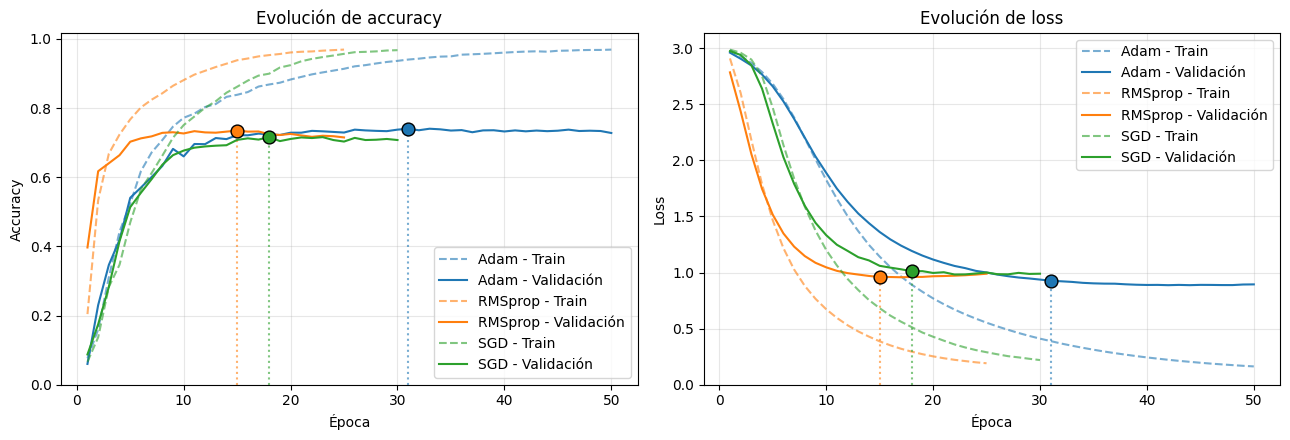

,Optimizador,Mejor época,Accuracy validación (%)
0,Adam,31,74.02
1,RMSprop,15,73.49
2,SGD,18,71.59


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

colores = {
    "Adam": "tab:blue",
    "RMSprop": "tab:orange",
    "SGD": "tab:green"
}

for optimizer_name, info in mejores_modelos.items():

    trial_number = info["trial_number"]
    mejor_epoca = info["best_epoch"]

    run_name = (
        f"optuna_{optimizer_name.lower()}_"
        f"50ep_es8_{trial_number}"
    )

    history_path = RESULTS_DIR / f"{run_name}.csv"
    history = pd.read_csv(history_path)

    color = colores[optimizer_name]


    # ACCURACY
    axes[0].plot(
        history["epoch"],
        history["train_acc"],
        linestyle="--",
        color=color,
        alpha=0.6,
        label=f"{optimizer_name} - Train"
    )

    axes[0].plot(
        history["epoch"],
        history["val_acc"],
        color=color,
        label=f"{optimizer_name} - Validación"
    )

    # Identificar la mejor época
    fila_mejor = history.loc[
        history["epoch"] == mejor_epoca
    ].iloc[0]

    mejor_acc = fila_mejor["val_acc"]
    loss_en_mejor_epoca = fila_mejor["val_loss"]

    # Punto en la mejor accuracy
    axes[0].scatter(
        mejor_epoca,
        mejor_acc,
        color=color,
        edgecolor="black",
        s=85,
        zorder=5
    )

    # Línea vertical hasta el punto
    axes[0].vlines(
        mejor_epoca,
        ymin=0,
        ymax=mejor_acc,
        color=color,
        linestyle=":",
        alpha=0.6
    )


    # LOSS
    axes[1].plot(
        history["epoch"],
        history["train_loss"],
        linestyle="--",
        color=color,
        alpha=0.6,
        label=f"{optimizer_name} - Train"
    )

    axes[1].plot(
        history["epoch"],
        history["val_loss"],
        color=color,
        label=f"{optimizer_name} - Validación"
    )

    # Marcar la pérdida en la época seleccionada
    axes[1].scatter(
        mejor_epoca,
        loss_en_mejor_epoca,
        color=color,
        edgecolor="black",
        s=85,
        zorder=5
    )

    axes[1].vlines(
        mejor_epoca,
        ymin=0,
        ymax=loss_en_mejor_epoca,
        color=color,
        linestyle=":",
        alpha=0.6
    )


# FORMATO
axes[0].set_title("Evolución de accuracy")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(bottom=0)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("Evolución de loss")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].set_ylim(bottom=0)
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()



# Tabla resumen de las épocas seleccionadas
resumen_mejores = []

for optimizer_name, info in mejores_modelos.items():
    resumen_mejores.append({
        "Optimizador": optimizer_name,
        "Mejor época": info["best_epoch"],
        "Accuracy validación (%)": info["val_acc"] * 100
    })

df_resumen_mejores = pd.DataFrame(resumen_mejores)

df_resumen_mejores = (
    df_resumen_mejores
    .sort_values("Accuracy validación (%)", ascending=False)
    .reset_index(drop=True)
)

display(
    df_resumen_mejores.style.format({
        "Accuracy validación (%)": "{:.2f}"
    })
)

Para cada optimizador, se seleccionó el trial que alcanzó la mayor *accuracy* sobre el conjunto de validación durante la búsqueda de hiperparámetros realizada con Optuna. Dentro de ese trial, se identificó la época en la que se obtuvo la máxima *accuracy* de validación y se conservaron los pesos del modelo correspondientes a dicha época.

El entrenamiento incorporó un mecanismo de *early stopping*, que detuvo el proceso cuando la pérdida de validación (*validation loss*) no mejoró durante 8 épocas consecutivas. Por lo tanto, el criterio de selección del mejor modelo fue la máxima *accuracy* de validación, mientras que el criterio de detención del entrenamiento fue la evolución de la pérdida de validación.

Entre las configuraciones evaluadas, Adam obtuvo la mayor *accuracy* de validación (74,02 %) en la época 31, seguido de RMSprop (73,49 %) en la época 15 y SGD (71,59 %) en la época 18.

## 7.2 Análisis de trials

,Optimizador,Total,Completados,Podados,Fallidos,Tiempo búsqueda (min)
0,Adam,17,11,6,0,2.57
1,RMSprop,17,12,5,0,1.84
2,SGD,17,9,8,0,3.37


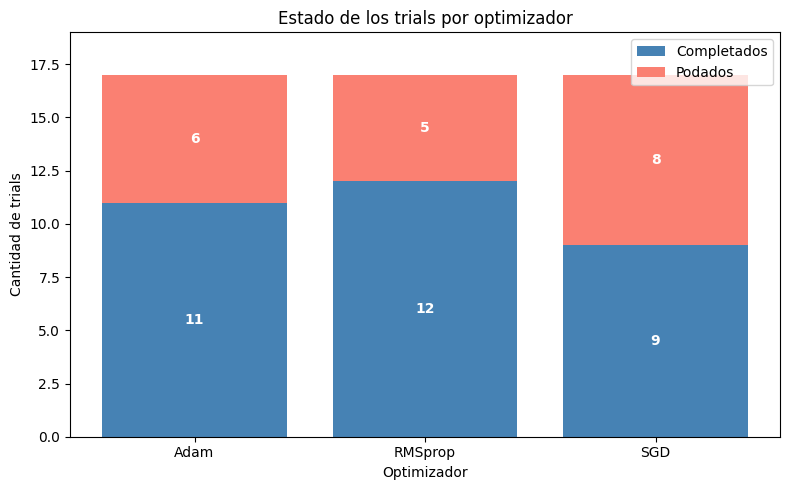

In [ ]:
resumen_trials = []

for optimizer_name, study in studies.items():
    trials = study.trials

    resumen_trials.append({
        "Optimizador": optimizer_name,
        "Total": len(trials),
        "Completados": sum(
            t.state == TrialState.COMPLETE for t in trials
        ),
        "Podados": sum(
            t.state == TrialState.PRUNED for t in trials
        ),
        "Fallidos": sum(
            t.state == TrialState.FAIL for t in trials
        ),
        "Tiempo búsqueda (min)": sum(
            t.duration.total_seconds()
            for t in trials
            if t.duration is not None
        ) / 60
    })

df_trials = pd.DataFrame(resumen_trials)
display(df_trials.round(2))


# gráfico de barras
fig, ax = plt.subplots(figsize=(8, 5))

optimizadores = df_trials["Optimizador"]
completados = df_trials["Completados"]
podados = df_trials["Podados"]

# Barras apiladas
ax.bar(
    optimizadores,
    completados,
    label="Completados",
    color="steelblue"
)

ax.bar(
    optimizadores,
    podados,
    bottom=completados,
    label="Podados",
    color="salmon"
)

# Cantidades dentro de cada segmento
for i, (c, p) in enumerate(zip(completados, podados)):
    ax.text(i, c / 2, str(c),
            ha="center", va="center",
            color="white", fontweight="bold")

    ax.text(i, c + p / 2, str(p),
            ha="center", va="center",
            color="white", fontweight="bold")

ax.set_title("Estado de los trials por optimizador")
ax.set_xlabel("Optimizador")
ax.set_ylabel("Cantidad de trials")
ax.set_ylim(0, 19)
ax.legend()

plt.tight_layout()
plt.show()

Habíamos configurado: 17 trials por optimizador, 51 en total.

De los 51 trials realizados, 32 se completaron y 19 fueron podados. No hubo trials fallidos.

SGD presentó la mayor cantidad de trials podados (8), seguido de Adam (6) y RMSprop (5). Esto indica que el mecanismo de pruning descartó más configuraciones de SGD durante la búsqueda, pero no demuestra por sí solo que SGD sea un optimizador peor.

También observamos que la búsqueda de SGD llevó más tiempo total (3,37 minutos), a pesar de que su mejor modelo tuvo el entrenamiento individual más corto. Esto se debe a que el tiempo total depende de todos los trials evaluados, no solamente del ganador.

## 7.3 Comparación de arquitecturas

In [ ]:
from optuna.trial import TrialState

,Optimizador,Trial,Accuracy validación (%),Capas ocultas,Neuronas por capa,Activación,Parámetros entrenables
0,Adam,4,74.02,1,[256],sigmoid,"2,565,396"
1,Adam,7,73.84,1,[64],tanh,"641,364"
2,Adam,16,73.71,1,[256],relu,"2,565,396"
3,RMSprop,15,73.49,1,[32],sigmoid,"320,692"
4,Adam,2,73.27,1,[32],relu,"320,692"
5,Adam,8,73.22,1,[64],relu,"641,364"
6,RMSprop,4,73.09,1,[256],sigmoid,"2,565,396"
7,Adam,11,72.34,1,[32],tanh,"320,692"
8,RMSprop,12,72.07,1,[32],relu,"320,692"
9,SGD,16,71.59,1,[64],tanh,"641,364"


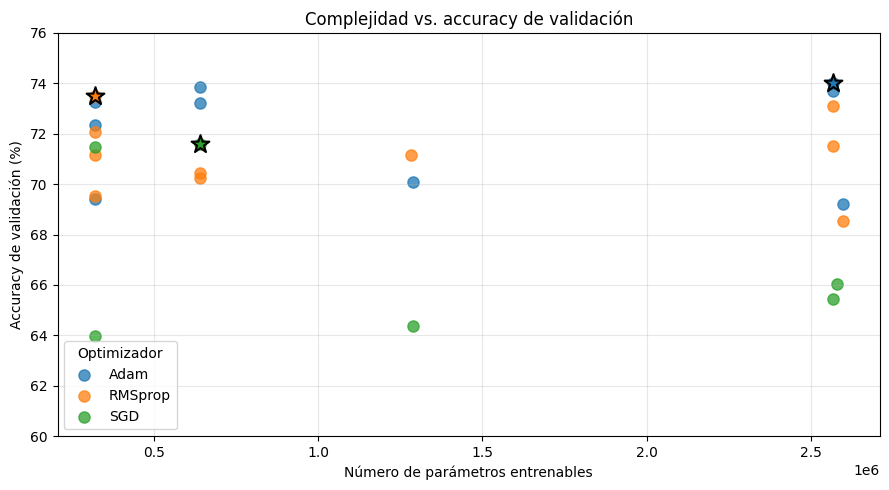

In [ ]:
resultados_arquitecturas = []

for optimizer_name, study in studies.items():

    for trial in study.trials:

        if trial.state != TrialState.COMPLETE:
            continue

        resultados_arquitecturas.append({
            "Optimizador": optimizer_name,
            "Trial": trial.number,
            "Accuracy validación (%)": trial.value * 100,
            "Capas ocultas": trial.params["n_layers"],
            "Neuronas por capa": trial.user_attrs.get("hidden_layers"),
            "Activación": trial.params["activation"],
            "Parámetros entrenables": trial.user_attrs.get("n_params")
        })

df_arquitecturas = pd.DataFrame(resultados_arquitecturas)

# Ordenar por mejor accuracy de validación
df_arquitecturas = (
    df_arquitecturas
    .sort_values("Accuracy validación (%)", ascending=False)
    .reset_index(drop=True)
)

display(
    df_arquitecturas.style.format({
        "Accuracy validación (%)": "{:.2f}",
        "Parámetros entrenables": "{:,.0f}"
    })
)


# gráfico
df_competitivos = df_arquitecturas[
    df_arquitecturas["Accuracy validación (%)"] >= 60
]

fig, ax = plt.subplots(figsize=(9, 5))

for optimizer_name, grupo in df_competitivos.groupby("Optimizador"):
    ax.scatter(
        grupo["Parámetros entrenables"],
        grupo["Accuracy validación (%)"],
        label=optimizer_name,
        color=colores[optimizer_name],
        alpha=0.75,
        s=65
    )

for optimizer_name, info in mejores_modelos.items():

    mejor = df_competitivos[
        (df_competitivos["Optimizador"] == optimizer_name) &
        (df_competitivos["Trial"] == info["trial_number"])
    ].iloc[0]

    ax.scatter(
        mejor["Parámetros entrenables"],
        mejor["Accuracy validación (%)"],
        color=colores[optimizer_name],
        marker="*",
        edgecolor="black",
        linewidth=1.5,
        s=180,
        zorder=5
    )

ax.set_title("Complejidad vs. accuracy de validación")
ax.set_xlabel("Número de parámetros entrenables")
ax.set_ylabel("Accuracy de validación (%)")
ax.set_ylim(60, 76)
ax.grid(alpha=0.3)
ax.legend(title="Optimizador")

plt.tight_layout()
plt.show()

Al comparar los 32 trials completados, se observa un predominio de Adam entre las configuraciones de mayor rendimiento: cuatro de los cinco mejores resultados corresponden a este optimizador, mientras que el mejor modelo de SGD aparece recién en la décima posición.

En cuanto a la arquitectura, los 16 modelos con mayor accuracy de validación utilizaron una sola capa oculta. El mejor modelo de dos capas alcanzó un 70,08 %, mientras que las configuraciones de tres capas que completaron el entrenamiento presentaron accuracies cercanas al nivel esperado por azar. Esto sugiere que, dentro de las configuraciones evaluadas, las arquitecturas más simples obtuvieron mejores resultados.

Por otro lado, el gráfico muestra que una mayor cantidad de parámetros entrenables no garantizó una mejor accuracy. Por ejemplo, Adam alcanzó un 74,02 % con aproximadamente 2,57 millones de parámetros, pero también obtuvo un 73,84 % con 641 mil parámetros. Asimismo, RMSprop consiguió un 73,49 % utilizando solamente 321 mil parámetros.

A partir de los resultados de la búsqueda con Optuna, se seleccionó la configuración que alcanzó la mayor accuracy de validación. El modelo elegido correspondió al **trial 4 de Adam**, con una capa oculta de 256 neuronas y activación Sigmoid, que obtuvo una accuracy de validación del 74,02 % en la época 31.

Esta selección determina la arquitectura, los hiperparámetros de entrenamiento y la cantidad de épocas que se utilizarán en el entrenamiento definitivo. Posteriormente, la red se inicializará nuevamente y se entrenará sobre el conjunto completo de entrenamiento, sin utilizar los documentos de test para ajustar sus parámetros.

In [ ]:
# Seleccionamos el modelo con mayor accuracy de validación
mejor_optimizador = df_resultados.loc[
    df_resultados["Accuracy validación (%)"].idxmax(),
    "Optimizador"
]

modelo_seleccionado = mejores_modelos[mejor_optimizador]

print("Modelo seleccionado:", mejor_optimizador)
print("Trial:", modelo_seleccionado["trial_number"])
print(f"Accuracy validación: {modelo_seleccionado['val_acc'] * 100:.2f}%")
print("Mejor época:", modelo_seleccionado["best_epoch"])
print("Checkpoint:", modelo_seleccionado["checkpoint_path"])

Modelo seleccionado: Adam
Trial: 4
Accuracy validación: 74.02%
Mejor época: 31
Checkpoint: /content/drive/MyDrive/Facultad documentos/20266/2C/16.32 Redes neuronales/tp/TP2/modelos/optuna_adam_50ep_es8_4_best.pth


# 8. Experimento de sobreajuste

Para estudiar el sobreajuste, se entrena una MLP con tres capas ocultas de 256, 128 y 64 neuronas, utilizando activación ReLU durante 100 épocas, sin *early stopping*. El objetivo es observar cómo evolucionan las métricas de entrenamiento y validación cuando se prolonga el entrenamiento de una red con mayor capacidad.

In [ ]:
# Configuración del experimento de sobreajuste

OVERFIT_EPOCHS = 100
OVERFIT_BATCH_SIZE = 64
OVERFIT_LR = 0.001

modelo_overfit = MLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    hidden_layers=[256, 128, 64],
    activation="relu"
)

optimizador_overfit = torch.optim.Adam(
    modelo_overfit.parameters(),
    lr=OVERFIT_LR,
    weight_decay=0.0
)

train_loader_overfit = DataLoader(
    train_dataset,
    batch_size=OVERFIT_BATCH_SIZE,
    shuffle=True
)

val_loader_overfit = DataLoader(
    val_dataset,
    batch_size=OVERFIT_BATCH_SIZE,
    shuffle=False
)

history_overfit = train_mlp_model(
    model=modelo_overfit,
    train_loader=train_loader_overfit,
    val_loader=val_loader_overfit,
    optimizer=optimizador_overfit,
    epochs=OVERFIT_EPOCHS,
    run_name="experimento_overfitting",
    save_results=True,
    save_model=False,
    early_stopping_patience=None
)

[experimento_overfitting] Epoch 1/100 | train_acc=0.2715 | val_acc=0.5285 | val_loss=1.5300 | tiempo=1.07s
[experimento_overfitting] Epoch 2/100 | train_acc=0.6932 | val_acc=0.6416 | val_loss=1.2248 | tiempo=0.68s
[experimento_overfitting] Epoch 3/100 | train_acc=0.8654 | val_acc=0.6478 | val_loss=1.3044 | tiempo=0.59s
[experimento_overfitting] Epoch 4/100 | train_acc=0.9367 | val_acc=0.6390 | val_loss=1.5274 | tiempo=0.60s
[experimento_overfitting] Epoch 5/100 | train_acc=0.9641 | val_acc=0.6270 | val_loss=1.7450 | tiempo=0.60s
[experimento_overfitting] Epoch 6/100 | train_acc=0.9697 | val_acc=0.6266 | val_loss=1.9235 | tiempo=0.60s
[experimento_overfitting] Epoch 7/100 | train_acc=0.9708 | val_acc=0.6217 | val_loss=2.0043 | tiempo=0.59s
[experimento_overfitting] Epoch 8/100 | train_acc=0.9722 | val_acc=0.6253 | val_loss=2.1101 | tiempo=0.60s
[experimento_overfitting] Epoch 9/100 | train_acc=0.9722 | val_acc=0.6262 | val_loss=2.1810 | tiempo=0.60s
[experimento_overfitting] Epoch 10/10

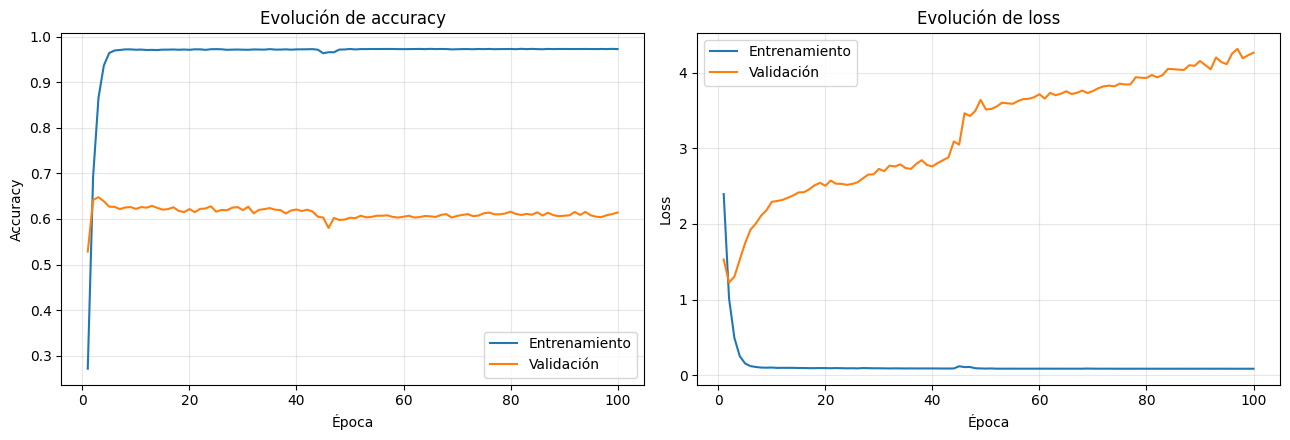

Época de menor val_loss: 2
Época de mayor val_acc: 3
Accuracy train final: 97.28%
Accuracy validación final: 61.42%
Brecha final: 35.86 p.p.
Train loss final: 0.0864
Val loss final: 4.2623


In [ ]:
history_df = pd.DataFrame(history_overfit)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Accuracy
axes[0].plot(
    history_df["epoch"],
    history_df["train_acc"],
    label="Entrenamiento"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_acc"],
    label="Validación"
)

axes[0].set_title("Evolución de accuracy")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Loss
axes[1].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Entrenamiento"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validación"
)

axes[1].set_title("Evolución de loss")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()




# Época con menor pérdida de validación
idx_min_loss = history_df["val_loss"].idxmin()

# Época con mayor accuracy de validación
idx_max_acc = history_df["val_acc"].idxmax()

# Última época
ultima = history_df.iloc[-1]

print("Época de menor val_loss:",
      int(history_df.loc[idx_min_loss, "epoch"]))

print("Época de mayor val_acc:",
      int(history_df.loc[idx_max_acc, "epoch"]))

print(f"Accuracy train final: {ultima['train_acc'] * 100:.2f}%")
print(f"Accuracy validación final: {ultima['val_acc'] * 100:.2f}%")

print(
    f"Brecha final: "
    f"{(ultima['train_acc'] - ultima['val_acc']) * 100:.2f} p.p."
)

print(f"Train loss final: {ultima['train_loss']:.4f}")
print(f"Val loss final: {ultima['val_loss']:.4f}")

El entrenamiento de la MLP durante 100 épocas permitió observar un comportamiento claro de sobreajuste. La accuracy de entrenamiento aumentó rápidamente hasta estabilizarse alrededor del 97 %, mientras que la accuracy de validación alcanzó su máximo de 64,78 % en la época 3 y posteriormente se mantuvo aproximadamente entre el 60 % y el 63 %, sin mejoras sostenidas.

La evolución de la función de pérdida refuerza esta observación. Mientras que la pérdida de entrenamiento disminuyó hasta 0,0864, la pérdida de validación alcanzó su mínimo de 1,2248 en la época 2 y luego aumentó progresivamente hasta 4,2623 al finalizar el entrenamiento. Como resultado, la brecha entre las accuracies de entrenamiento y validación fue de 35,86 puntos porcentuales en la última época.

Estos resultados evidencian que el modelo logró ajustarse muy bien a los datos de entrenamiento, pero no consiguió generalizar de manera equivalente a los datos de validación. Además, muestran que prolongar el entrenamiento una vez alcanzado el mejor rendimiento de validación puede incrementar el sobreajuste sin producir mejoras en la clasificación.

El experimento permite justificar el uso de *early stopping* en los entrenamientos anteriores, como mecanismo para limitar el entrenamiento innecesario y reducir el deterioro de la generalización.

# 9. Entrenamiento y evaluación final

Una vez seleccionada la mejor configuración mediante Optuna, se reconstruye la MLP y se entrena desde cero utilizando el conjunto completo de entrenamiento. Finalmente, se evalúa su rendimiento sobre test y se compara con el modelo de referencia del TP1.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [ ]:
# Recuperar la configuración seleccionada
params_final = modelo_seleccionado["params"]
trial_final = studies[mejor_optimizador].best_trial

hidden_layers_final = trial_final.user_attrs["hidden_layers"]
epochs_final = modelo_seleccionado["best_epoch"]

# Preprocesar todos los documentos de entrenamiento
train_full_proc = [
    preprocess_text(t, REMOVE_STOPWORDS, NORMALIZATION)
    for t in newsgroups_train.data
]

# Ajustar TF-IDF nuevamente, usando todo el entrenamiento
vectorizer_final = TfidfVectorizer(
    ngram_range=NGRAM_RANGE,
    max_features=MAX_FEATURES,
    min_df=MIN_DF
)

X_train_full = vectorizer_final.fit_transform(train_full_proc)

train_full_dataset = to_tensor_dataset(
    X_train_full,
    newsgroups_train.target
)

train_full_loader = DataLoader(
    train_full_dataset,
    batch_size=params_final["batch_size"],
    shuffle=True
)

print("Documentos de entrenamiento:", len(train_full_dataset))
print("Características TF-IDF:", X_train_full.shape[1])
print("Arquitectura:", hidden_layers_final)
print("Épocas:", epochs_final)

Documentos de entrenamiento: 11314
Características TF-IDF: 10000
Arquitectura: [256]
Épocas: 31


In [ ]:
# Reproducibilidad
torch.manual_seed(SEED)

# Reconstruir la arquitectura seleccionada
modelo_final = MLP(
    input_dim=X_train_full.shape[1],
    num_classes=NUM_CLASSES,
    hidden_layers=hidden_layers_final,
    activation=params_final["activation"]
).to(device)

# Reconstruir el optimizador
optimizer_final = torch.optim.Adam(
    modelo_final.parameters(),
    lr=params_final["lr"],
    betas=(params_final["beta1"], params_final["beta2"]),
    weight_decay=params_final["weight_decay"]
)

criterion = nn.CrossEntropyLoss()

# Entrenamiento definitivo
for epoch in range(epochs_final):

    modelo_final.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for xb, yb in train_full_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer_final.zero_grad()

        logits = modelo_final(xb)
        loss = criterion(logits, yb)

        loss.backward()
        optimizer_final.step()

        running_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        total += xb.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    print(
        f"Época {epoch+1}/{epochs_final} | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {train_acc:.4f}"
    )

print("\nEntrenamiento finalizado.")

Época 1/31 | Loss: 2.9756 | Accuracy: 0.0743
Época 2/31 | Loss: 2.9073 | Accuracy: 0.2007
Época 3/31 | Loss: 2.8202 | Accuracy: 0.3772
Época 4/31 | Loss: 2.6999 | Accuracy: 0.4946
Época 5/31 | Loss: 2.5328 | Accuracy: 0.5800
Época 6/31 | Loss: 2.3253 | Accuracy: 0.6602
Época 7/31 | Loss: 2.0994 | Accuracy: 0.6967
Época 8/31 | Loss: 1.8781 | Accuracy: 0.7428
Época 9/31 | Loss: 1.6778 | Accuracy: 0.7728
Época 10/31 | Loss: 1.5000 | Accuracy: 0.7869
Época 11/31 | Loss: 1.3465 | Accuracy: 0.8033
Época 12/31 | Loss: 1.2152 | Accuracy: 0.8122
Época 13/31 | Loss: 1.1019 | Accuracy: 0.8266
Época 14/31 | Loss: 1.0054 | Accuracy: 0.8360
Época 15/31 | Loss: 0.9223 | Accuracy: 0.8466
Época 16/31 | Loss: 0.8502 | Accuracy: 0.8538
Época 17/31 | Loss: 0.7874 | Accuracy: 0.8630
Época 18/31 | Loss: 0.7308 | Accuracy: 0.8702
Época 19/31 | Loss: 0.6807 | Accuracy: 0.8802
Época 20/31 | Loss: 0.6359 | Accuracy: 0.8882
Época 21/31 | Loss: 0.5955 | Accuracy: 0.8959
Época 22/31 | Loss: 0.5580 | Accuracy: 0.90

In [ ]:
# Preprocesamiento de los documentos de test
test_proc = [
    preprocess_text(t, REMOVE_STOPWORDS, NORMALIZATION)
    for t in newsgroups_test.data
]

# Transformación con el TF-IDF ajustado sobre entrenamiento
X_test_final = vectorizer_final.transform(test_proc)

test_final_dataset = to_tensor_dataset(
    X_test_final,
    newsgroups_test.target
)

test_final_loader = DataLoader(
    test_final_dataset,
    batch_size=64,
    shuffle=False
)

print("Documentos de test:", len(test_final_dataset))
print("Características TF-IDF:", X_test_final.shape[1])

Documentos de test: 7532
Características TF-IDF: 10000


In [ ]:
modelo_final.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for xb, yb in test_final_loader:

        xb = xb.to(device)

        logits = modelo_final(xb)
        predicciones = logits.argmax(dim=1)

        y_true.extend(yb.numpy())
        y_pred.extend(predicciones.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [ ]:
accuracy_test = accuracy_score(y_true, y_pred)
precision_test = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_test = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1_test = f1_score(y_true, y_pred, average="macro", zero_division=0)

df_metricas_test = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1-score macro"
    ],
    "Resultado (%)": [
        accuracy_test * 100,
        precision_test * 100,
        recall_test * 100,
        f1_test * 100
    ]
})

display(
    df_metricas_test.style.format({
        "Resultado (%)": "{:.2f}"
    })
)

print("\nReporte por clase:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=newsgroups_test.target_names,
        zero_division=0
    )
)

,Métrica,Resultado (%)
0,Accuracy,68.06
1,Precision macro,68.32
2,Recall macro,67.03
3,F1-score macro,67.31



Reporte por clase:

                          precision    recall  f1-score   support

             alt.atheism       0.53      0.51      0.52       319
           comp.graphics       0.60      0.63      0.62       389
 comp.os.ms-windows.misc       0.57      0.64      0.60       394
comp.sys.ibm.pc.hardware       0.64      0.63      0.63       392
   comp.sys.mac.hardware       0.72      0.65      0.69       385
          comp.windows.x       0.79      0.64      0.70       395
            misc.forsale       0.78      0.78      0.78       390
               rec.autos       0.76      0.69      0.72       396
         rec.motorcycles       0.47      0.79      0.59       398
      rec.sport.baseball       0.89      0.79      0.84       397
        rec.sport.hockey       0.90      0.89      0.89       399
               sci.crypt       0.84      0.71      0.77       396
         sci.electronics       0.63      0.56      0.59       393
                 sci.med       0.81      0.75      0.7

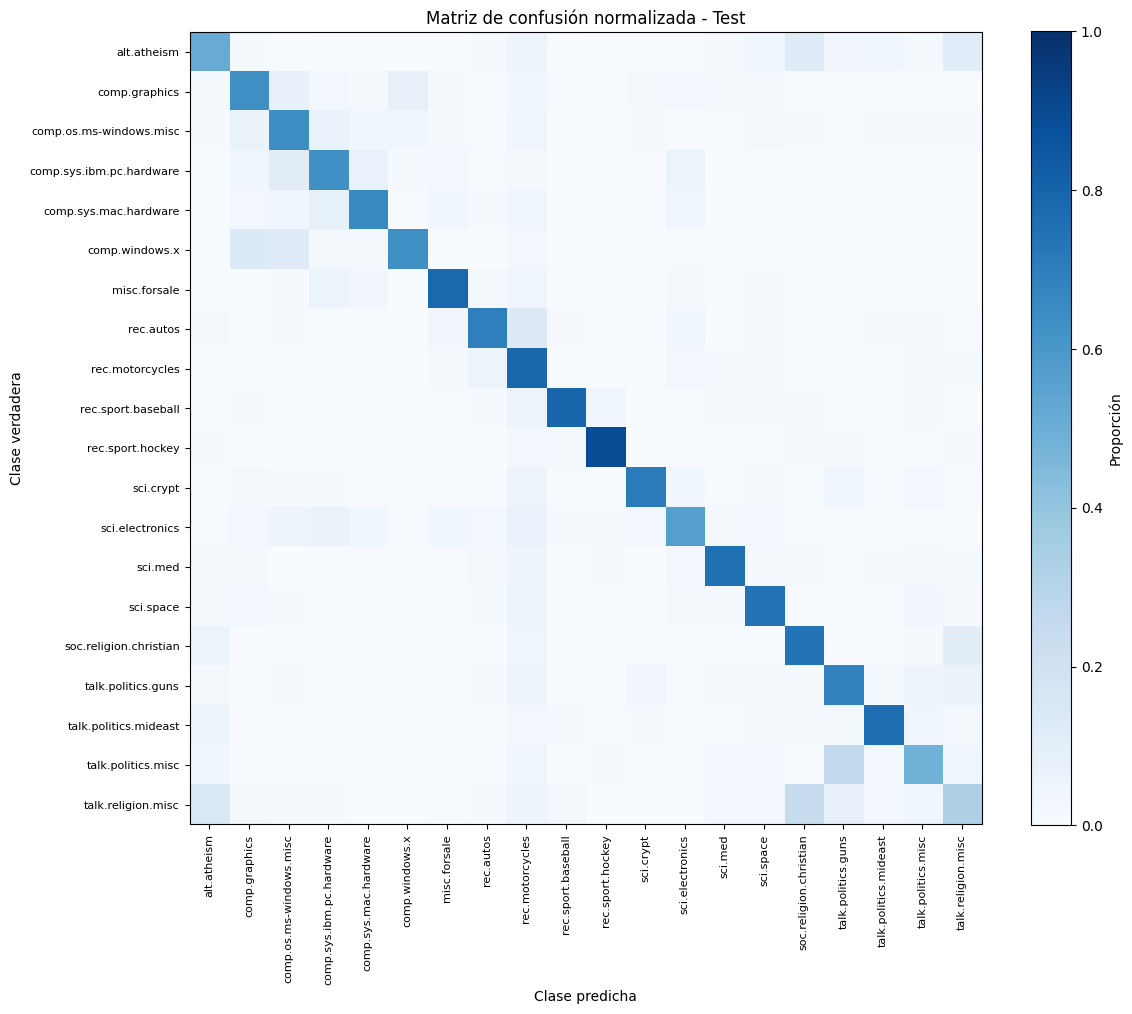

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))

ax.set_xticklabels(
    newsgroups_test.target_names,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    newsgroups_test.target_names,
    fontsize=8
)

ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase verdadera")
ax.set_title("Matriz de confusión normalizada - Test")

fig.colorbar(im, ax=ax, label="Proporción")

plt.tight_layout()
plt.show()

El modelo seleccionado mediante Optuna se reconstruyó y entrenó desde cero utilizando los 11.314 documentos del conjunto original de entrenamiento. Se mantuvieron la arquitectura y los hiperparámetros seleccionados, fijando el entrenamiento en 31 épocas, correspondientes a la mejor época de validación.

Una vez finalizado el entrenamiento, se evaluó el modelo sobre los 7.532 documentos del conjunto de test. Se obtuvo una **accuracy del 68,06 %**, una precision macro del 68,32 %, un recall macro del 67,03 % y un F1-score macro del 67,31 %.

El rendimiento presentó diferencias entre categorías. Los mayores F1-scores correspondieron a `rec.sport.hockey` (0,89) y `rec.sport.baseball` (0,84), mientras que `talk.religion.misc` obtuvo el menor valor (0,33).

La matriz de confusión muestra que parte de los errores se concentra entre categorías temáticamente relacionadas. Se observan confusiones entre distintas categorías de informática, entre temas políticos y entre categorías vinculadas con la religión. Esto sugiere que el modelo presenta mayores dificultades para distinguir textos que comparten vocabulario o contenido temático.

La accuracy de test fue 5,96 puntos porcentuales inferior a la mejor accuracy de validación obtenida durante Optuna (74,02 %). Sin embargo, estos resultados corresponden a modelos entrenados en condiciones diferentes: durante la búsqueda se utilizó una partición de entrenamiento y validación, mientras que el modelo definitivo se entrenó nuevamente sobre todos los documentos disponibles para entrenamiento.

En conjunto, los resultados muestran que la MLP logró aprender patrones relevantes para la clasificación multiclase de textos, aunque su capacidad de generalización presenta diferencias entre categorías.

## Comparación con el TP1

En el TP1 se implementó una regresión Softmax, un modelo lineal sin capas ocultas, que alcanzó una accuracy del 62,63 % sobre el conjunto de test de 20 Newsgroups. En el TP2 se utilizó una red neuronal MLP con una capa oculta de 256 neuronas y activación Sigmoid, que obtuvo una accuracy del 68,06 % sobre el mismo conjunto. Esto representa una mejora de **5,43 puntos porcentuales**.

Ambos modelos utilizaron una representación TF-IDF de hasta 10.000 características y la misma configuración de preprocesamiento. La principal diferencia arquitectónica es que la MLP incorpora una transformación no lineal de las características, mientras que la regresión Softmax establece directamente una relación lineal entre las entradas y los logits de las clases.

Sin embargo, la mejora observada no puede atribuirse exclusivamente a la arquitectura, ya que también cambiaron los hiperparámetros y las condiciones de entrenamiento.

En conclusión, **la MLP obtuvo un mejor rendimiento de clasificación que la referencia del TP1**, aunque los resultados no permiten determinar de manera aislada cuánto de esa mejora se debe a la incorporación de la capa oculta.